Checking TOA to altitude conservation for all EEI models

In [ ]:
import numpy as np
import sys, os
from SpaceBalls.postproc_EEI_estimation import get_true_EEI_time_series, get_subdir_EEI_truth
from SpaceBalls.radiation_fluxes_preprocessing import get_r_sun_jd_hist, get_solar_incoming_day_hist, get_EEI_truth_daily_jd_arrays, F_vec_to_Fr, get_toa_grid_from_rad_config
from SpaceBalls.radiation_settings import get_TSI_1AU, radiation_settings_from_EEI_truth_name
from SpaceBalls.sph_meshing import RegularLatLonGrid, QuadratureGrid, Grid
from SpaceBalls.utils import normal_smoother
from SpaceBalls.plotter import Plotter
from SpaceBalls.paths import MEDIA_DIR, OUTPUT_DIR
%matplotlib inline

def glq_n_to_l(n):
    return np.array(np.round(0.25 * (-3 + np.sqrt(1 + 8*n))), dtype=int)



def load_earth_map(grid_name, toa_grid_name, truth_name):

    return np.load(os.path.join(MEDIA_DIR, 'true_EEI', truth_name, 'day_0', integrated))


altitude_km = 800

regular_altitude_grids = [RegularLatLonGrid(altitude_km, n_lat=int(np.round(180*f)), 
                                                         n_lon=int(np.round(360*f)),
                                                         flattening=0) for f in np.logspace(-0.7, 0.5, 15)]
regular_altitude_grids = regular_altitude_grids[:-5]

n_points_glq = np.logspace(np.log10(regular_altitude_grids[0].n_points), 
                           np.log10(regular_altitude_grids[-1].n_points), 
                           len(regular_altitude_grids))
l_glq = glq_n_to_l(n_points_glq)
glq_altitude_grids = [RegularLatLonGrid(altitude_km, lmax=int(l), quad_type='GLQ',
                                       flattening=0) for l in l_glq]

womersley_altitude_grids = [QuadratureGrid(altitude_km, order=o, 
                                           default_womersley=True, 
                                           flattening=0) for o in np.arange(33, 325, 16)]

# EEI 3
EEI_name = 'EEI_truth_3'
rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
regular_toa_grids = [get_toa_grid_from_rad_config(rad_config, deg_bin_size=d) for d in (10, 5, 2.5, 1)]
n_points_reg_toa_grids = np.array([grid.n_points for grid in regular_toa_grids])
glq_toa_grids = [get_toa_grid_from_rad_config(rad_config, glq_order=l) for l in glq_n_to_l(n_points_reg_toa_grids)]
womersley_orders = np.array([51, 101, 151, 225, 325]) # np.round(np.sqrt(2*n_points_reg_toa_grids))
womersley_toa_grids = [get_toa_grid_from_rad_config(rad_config, quadrature_order=int(l), default_womersley=True) 
                        for l in womersley_orders]

# Earth Rgular grids


r vectors projected to ellipsoid
Loading TOA truth from grid_quad_n251
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
Loading TOA truth from grid_quad_n251
r vectors projected to ellipsoid
r vectors projected to ellipsoid
r vectors projected to ellipsoid
Loading TOA truth from grid_quad_n251
r vectors projected to ellipsoid
r vectors projected to ellipsoid


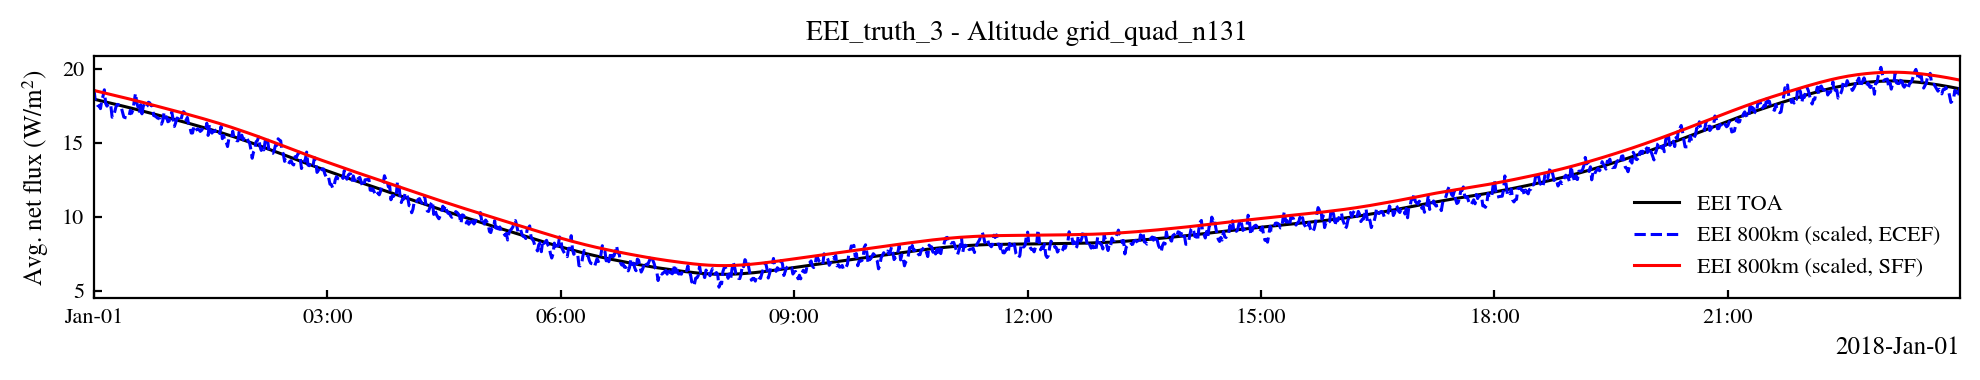

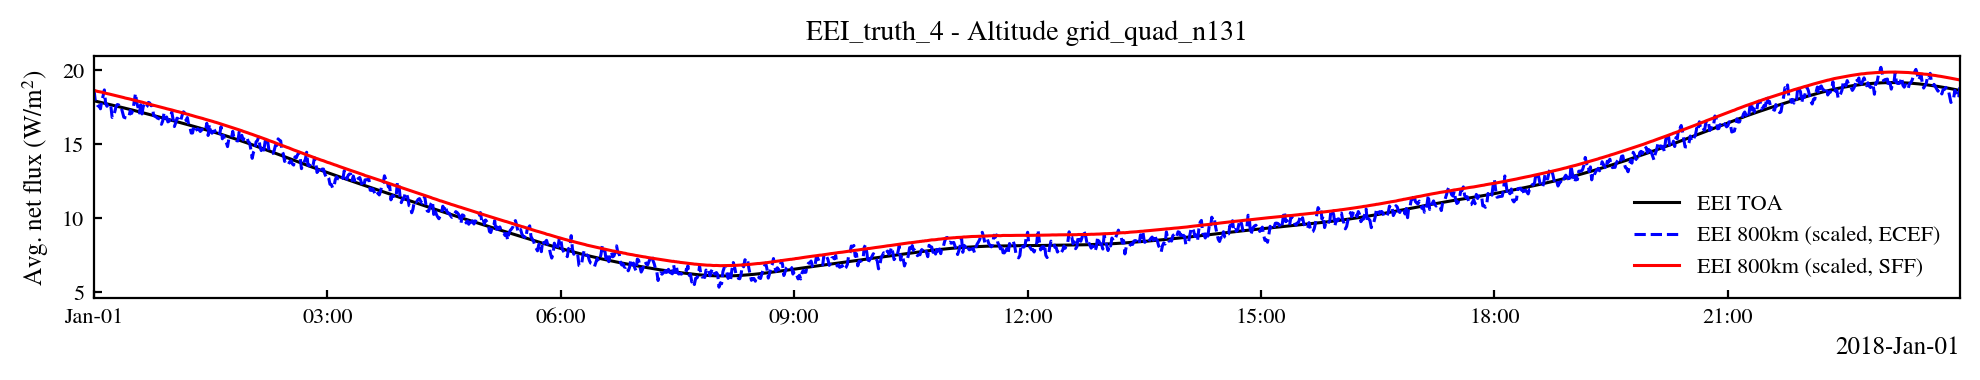

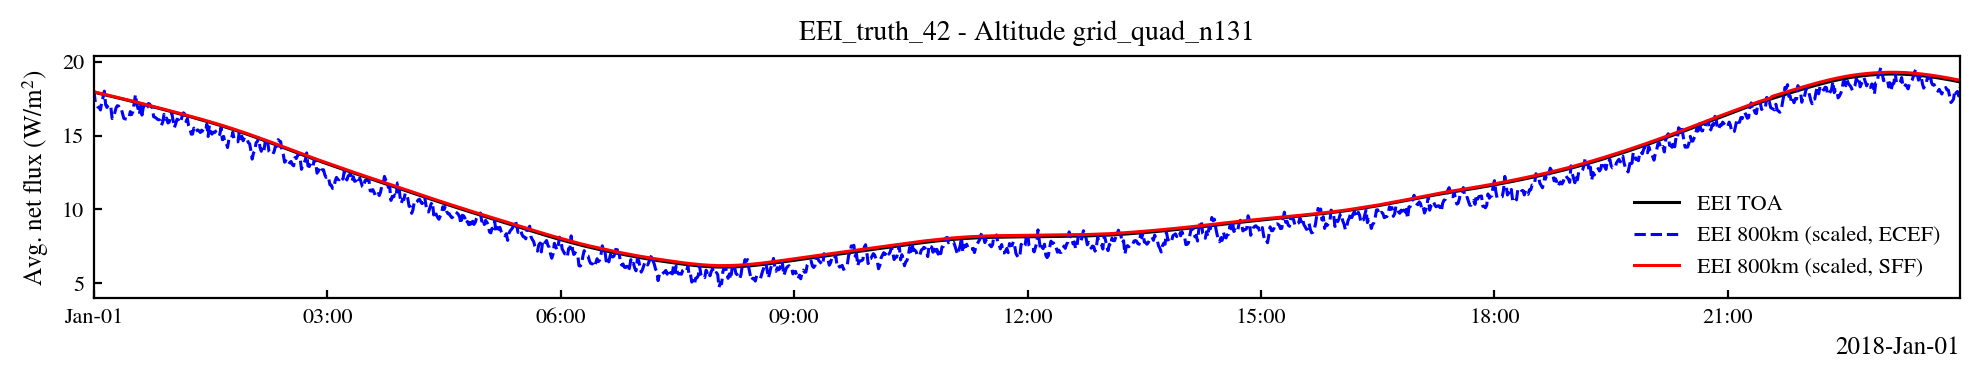

In [1]:
import numpy as np
import sys, os
from SpaceBalls.postproc_EEI_estimation import get_true_EEI_time_series, get_subdir_EEI_truth
from SpaceBalls.radiation_fluxes_preprocessing import get_r_sun_jd_hist, get_solar_incoming_day_hist, get_EEI_truth_daily_jd_arrays, F_vec_to_Fr, get_toa_grid_from_rad_config
from SpaceBalls.radiation_settings import get_TSI_1AU, radiation_settings_from_EEI_truth_name
from SpaceBalls.sph_meshing import QuadratureGrid, Grid
from SpaceBalls.utils import normal_smoother
from SpaceBalls.plotter import Plotter
%matplotlib inline

def get_EEI_altitude(EEI_name, grid_altitude: Grid, frame="ECEF"):
    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    toa_grid = get_toa_grid_from_rad_config(rad_config)
    EEI_altitude = []
    frame_tag = '' if frame=="ECEF" else "_SFF_accurate"

    for day_idx in range(n_days):
        # ECEF altitude:
        subdir_F = get_subdir_EEI_truth(EEI_name, 'daily_hist_net_F_800km'+frame_tag, grid_altitude.grid_name) 
        file_F_hist = os.path.join(subdir_F, 'day_'+str(day_idx)+'.npy')
        
        if os.path.exists(file_F_hist):
            daily_hist_F = np.load(file_F_hist)
            if np.shape(daily_hist_F)[1]==3:
                daily_hist_F = np.moveaxis(daily_hist_F, 1, 2)
            daily_hist_Fr = F_vec_to_Fr(daily_hist_F, grid_altitude.stacked_grid_u)
        else:
            subdir_Fr = get_subdir_EEI_truth(EEI_name, 'daily_hist_net_Fr_800km'+frame_tag, grid_altitude.grid_name) 
            daily_hist_Fr = np.load(os.path.join(subdir_Fr, 'day_'+str(day_idx)+'.npy'))
        EEI_altitude.append(grid_altitude.compute_surf_integral(daily_hist_Fr) / toa_grid.total_area)

    return np.concatenate(EEI_altitude)

# EEI truths with a/e max. D/O 45
EEI_names = ['EEI_truth_0', 'EEI_truth_1', 'EEI_truth_35']
grid_800km = QuadratureGrid(alt_km=800, order=325)

# EEI truths with a/e max. D/O 45
EEI_names = ['EEI_truth_3', 'EEI_truth_4', 'EEI_truth_42']
#grid_800km = QuadratureGrid(alt_km=800, order=201)
grid_800km = QuadratureGrid(alt_km=800, order=131)

n_days = 1

for EEI_name in EEI_names:
    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    full_jd_array = np.concatenate(get_EEI_truth_daily_jd_arrays(rad_config['jd_interval'])[:n_days])
    
    EEI_time_series = get_true_EEI_time_series(EEI_name, n_days)
    EEI_altitude_ECEF = get_EEI_altitude(EEI_name, grid_800km, frame="ECEF")
    EEI_altitude_SFF = get_EEI_altitude(EEI_name, grid_800km, frame="SFF")
    
    Plotter.plot_time_series(full_jd_array,
        {'EEI TOA': EEI_time_series,
         'EEI 800km (scaled, ECEF)': EEI_altitude_ECEF,
         'EEI 800km (scaled, SFF)': EEI_altitude_SFF
        },
        f_width=2.5, f_height=0.5,
        ylabel='Avg. net flux (W/m$^2$)',
        title=EEI_name + " - Altitude " + grid_800km.grid_name)    

# now when EEI truth 0 is recomputed in the SFF (F hist instead of Fr) we'll see if there was a bug or it just gives the same
# RESULT: No difference - original implementation had no bug. Bias is due to somethign else - likey grid alignment and shadow transition

# next check: when day 0 is recomputed in the SFF with a quad325 grid, we'll see if the difference decreases
# if it does, it is worth exploring the idea of placing a ring of high mesh density around the eclipse transition
# RESULT: it does decrease, by a lot! grid_quad_n131 is not enough to accurately capture EEI at altitude (at least on daily scales)
# but then, why did the estimation results barely change between using quad_n131 and quad_n325?

# checks to do now:
# - estimation wrt integrated SFF_accurate truth !!!
# - check conservation of Earth vs. Solar flux separately - if Earth F is conserved to altitude on a quad131 grid, then the problem is almost certainly the eclipse transition

Checking TOA to altitude conservation for all EEI models, solar and Earth split

r vectors projected to ellipsoid
Getting smooth daily ae hist...
r vectors projected to ellipsoid
r vectors projected to ellipsoid
Getting smooth daily ae hist...
r vectors projected to ellipsoid
r vectors projected to ellipsoid
Getting smooth daily ae hist...
r vectors projected to ellipsoid


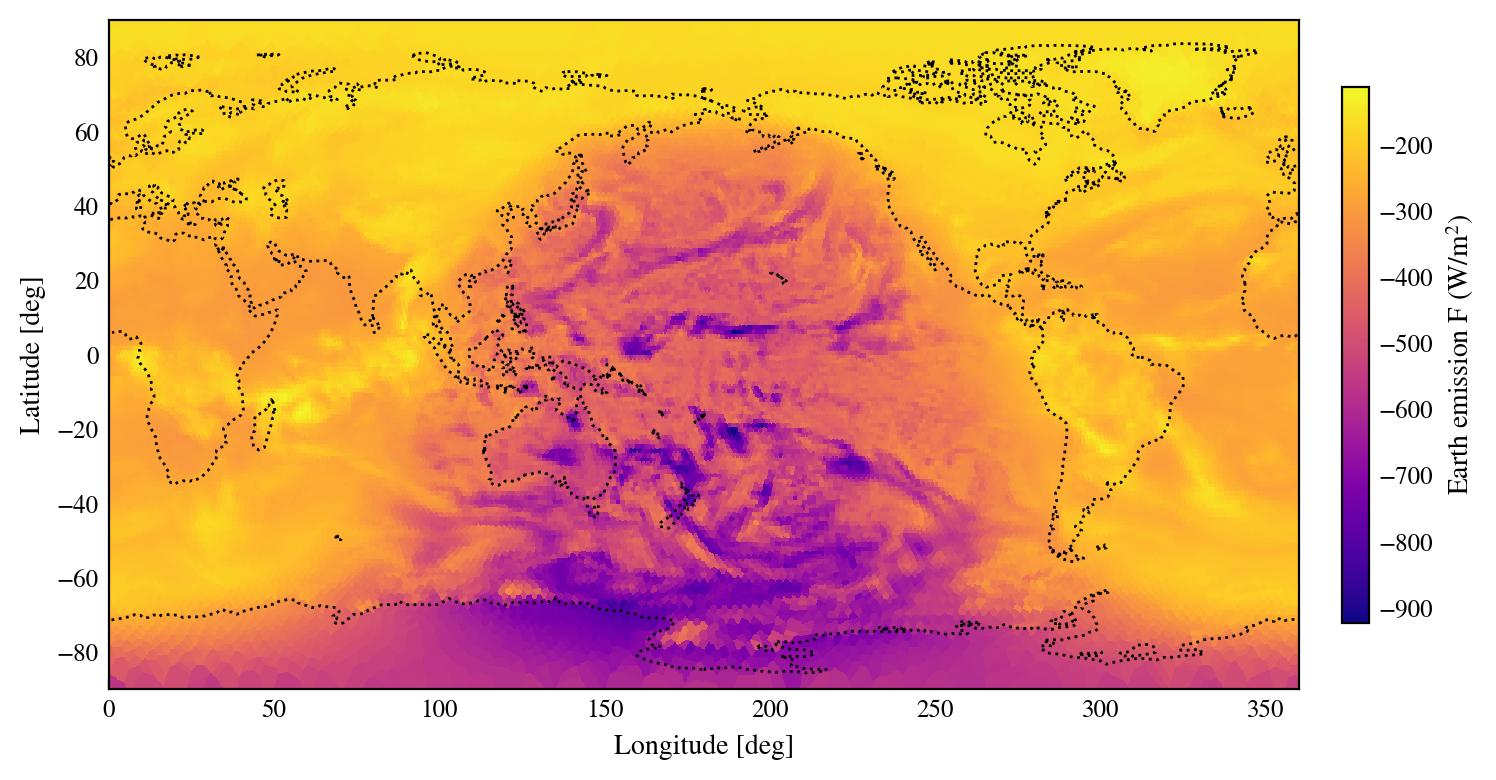

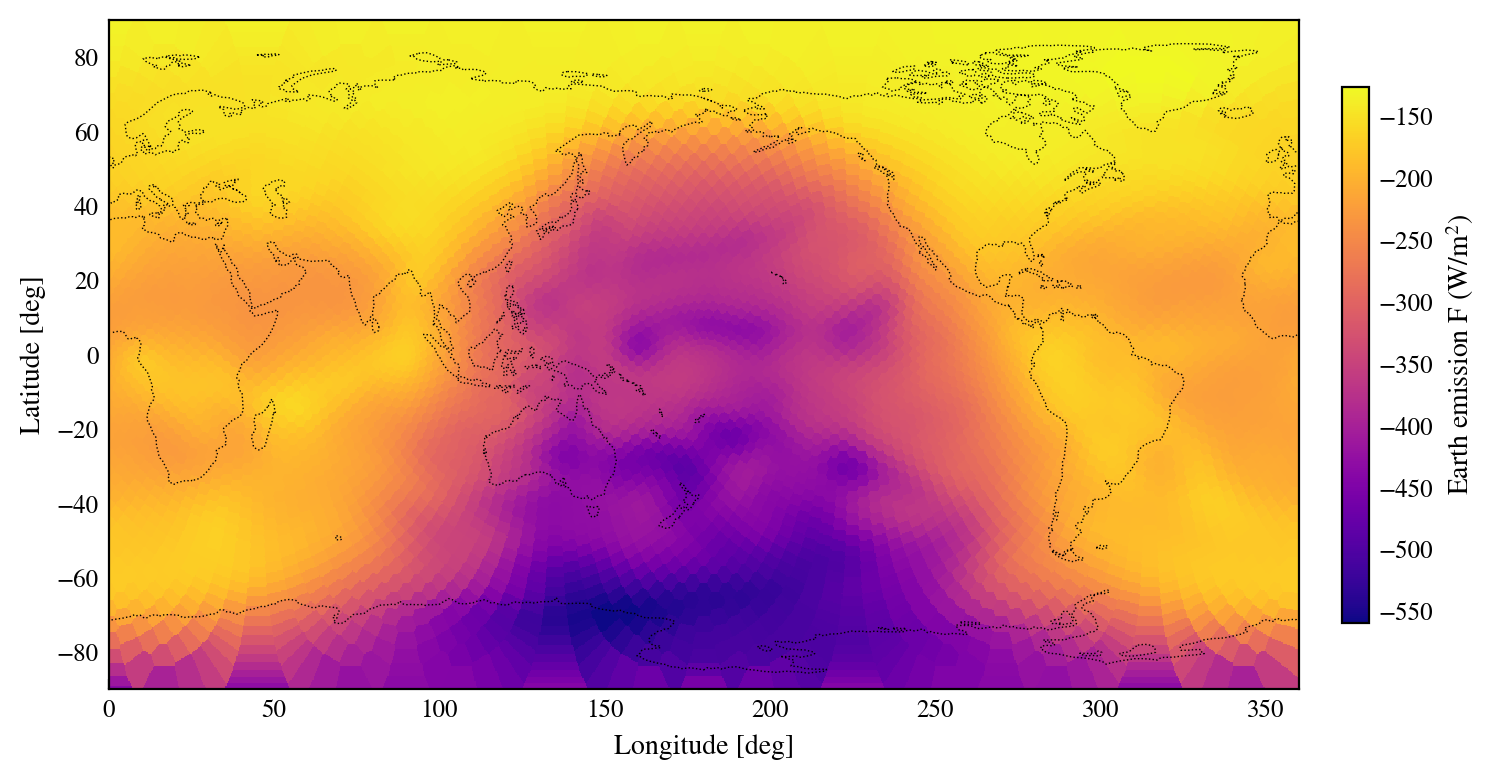

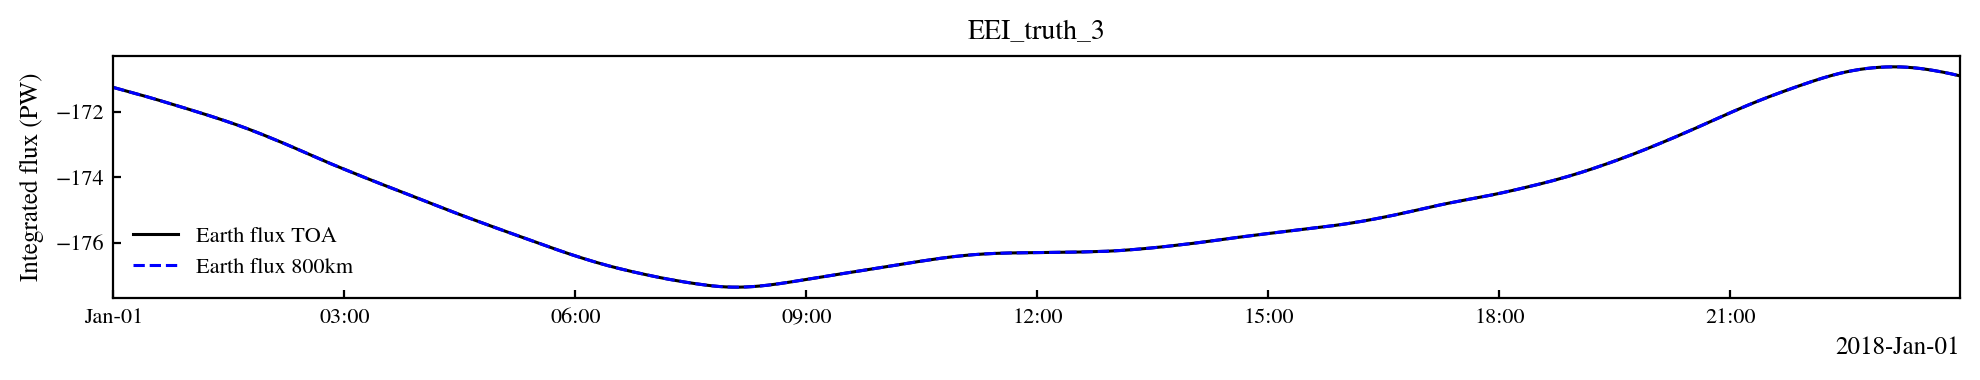

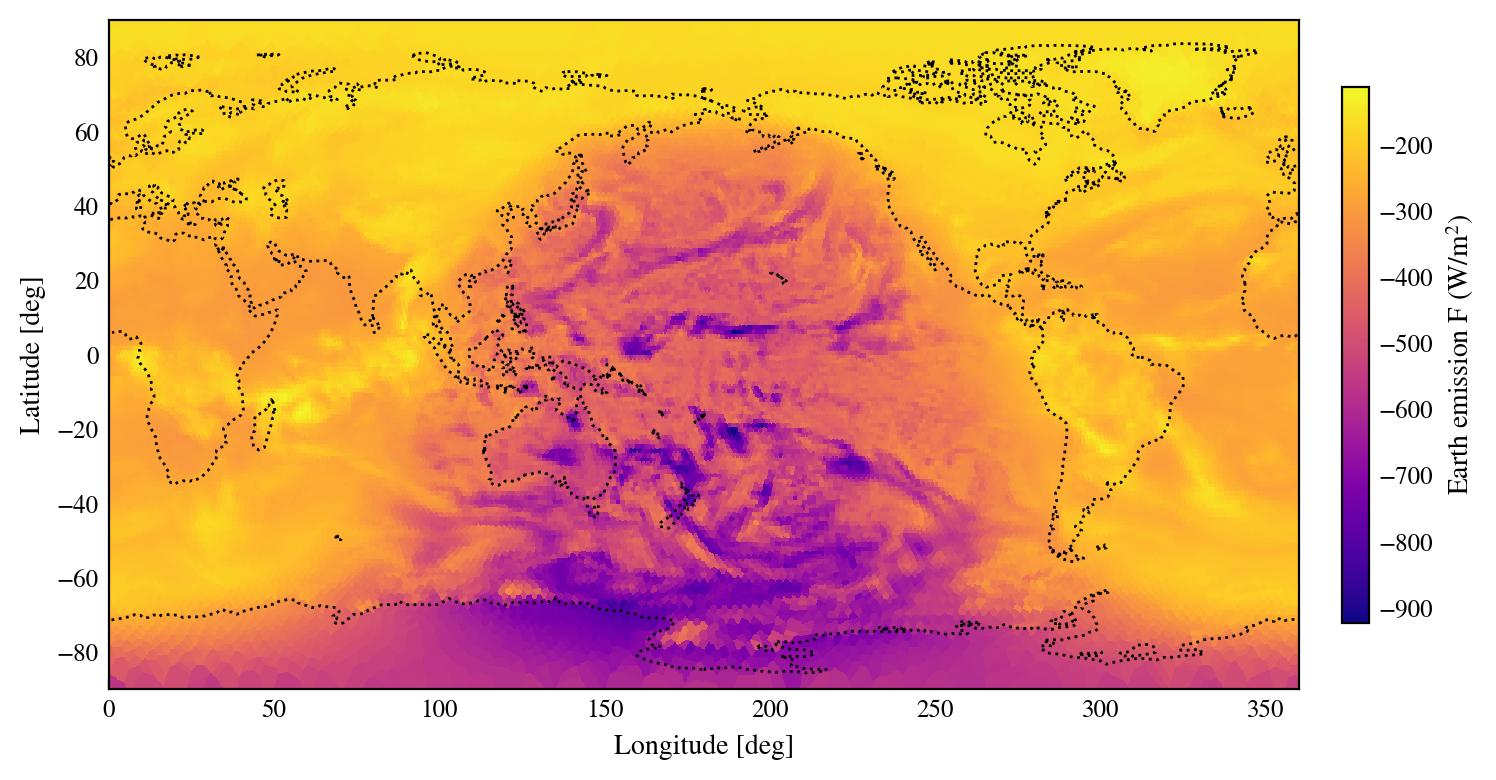

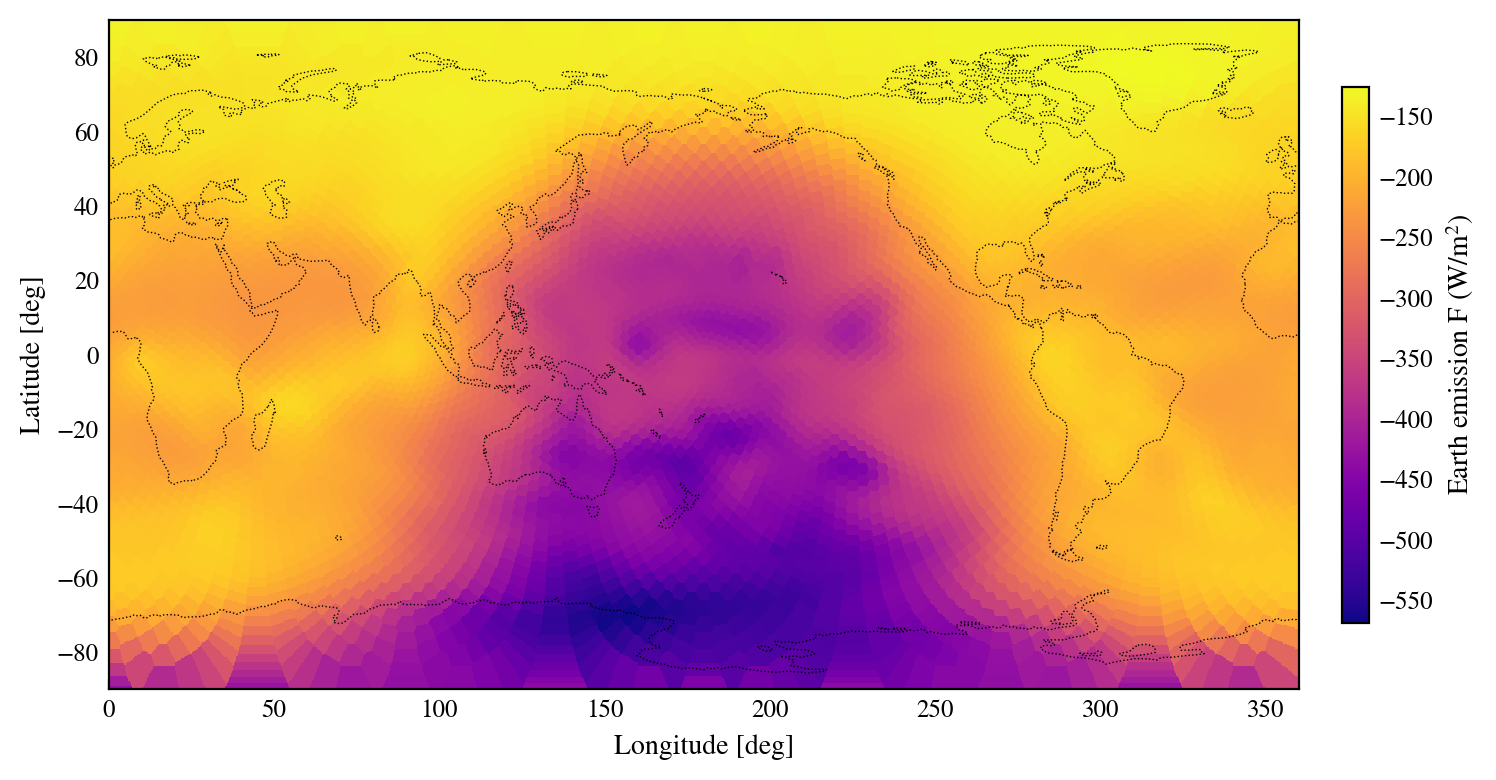

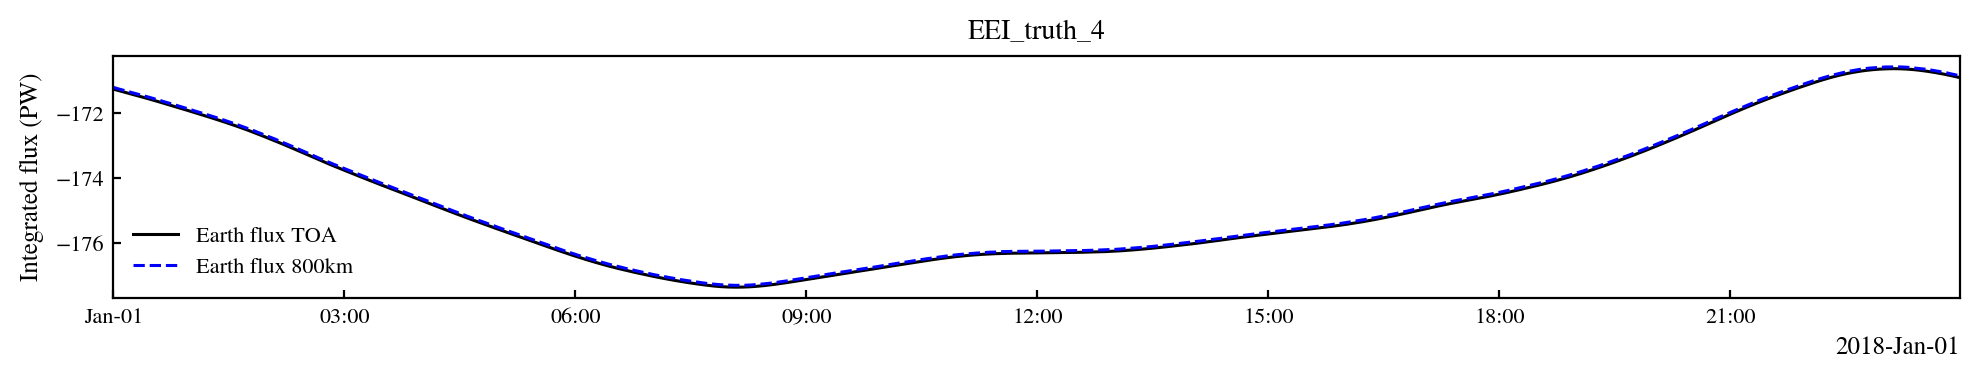

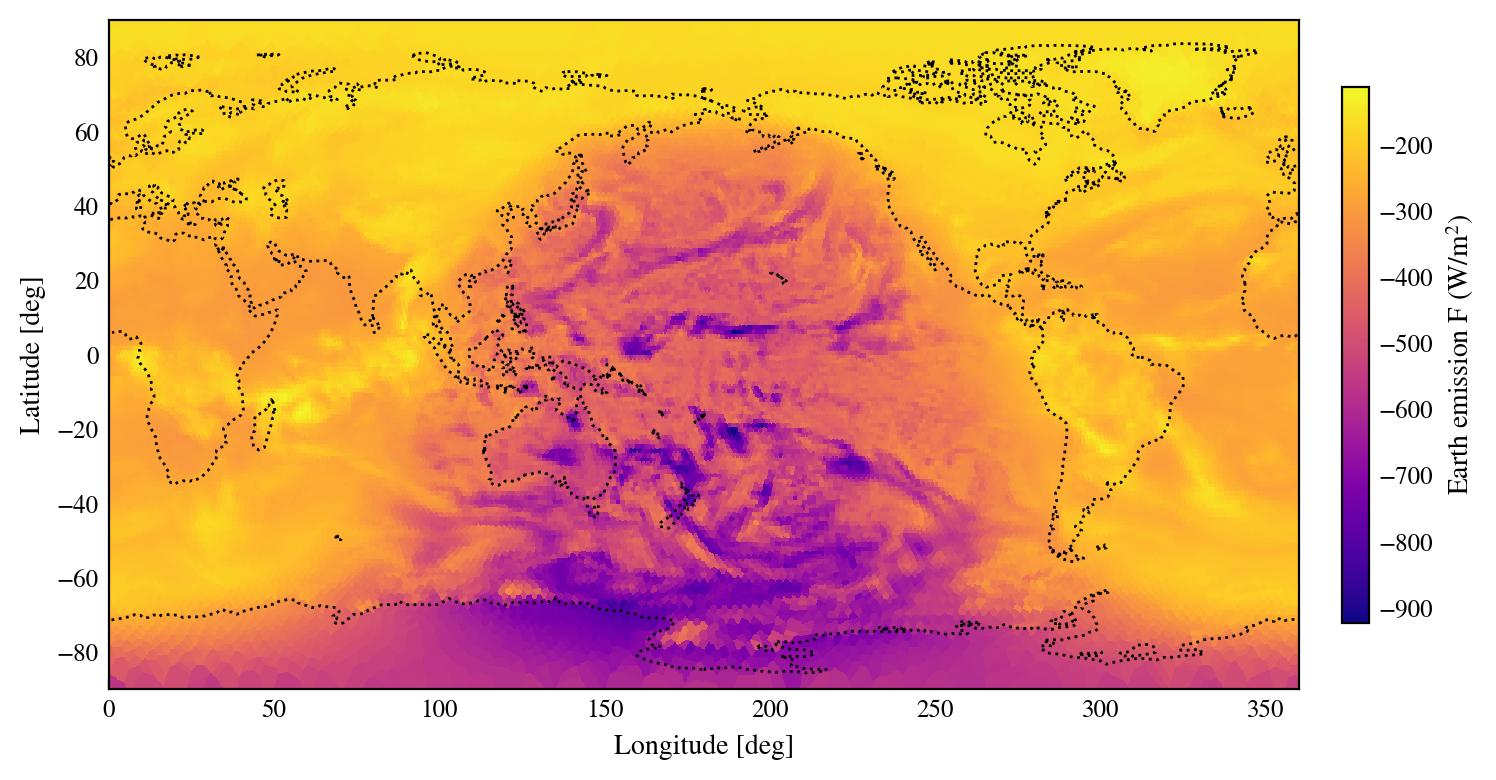

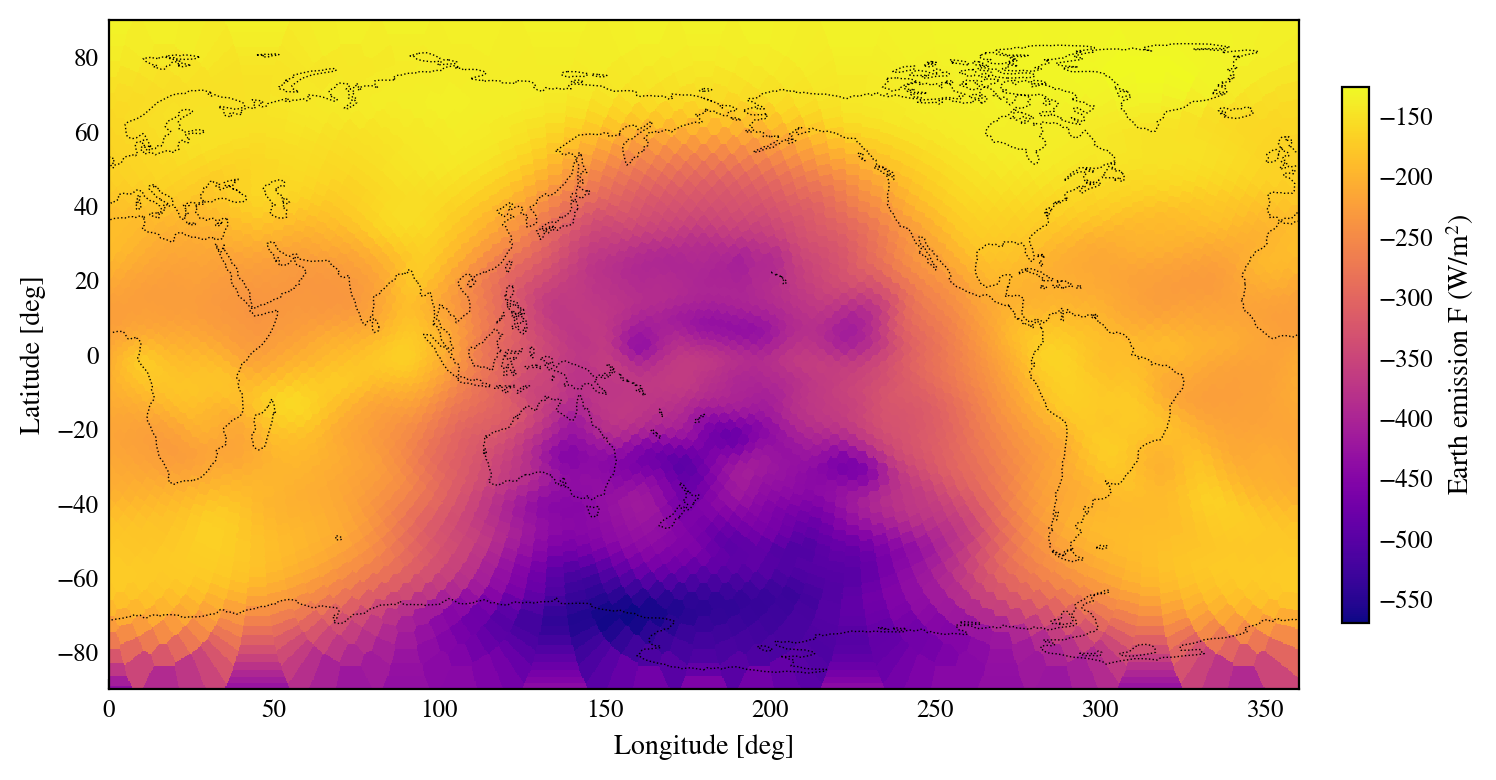

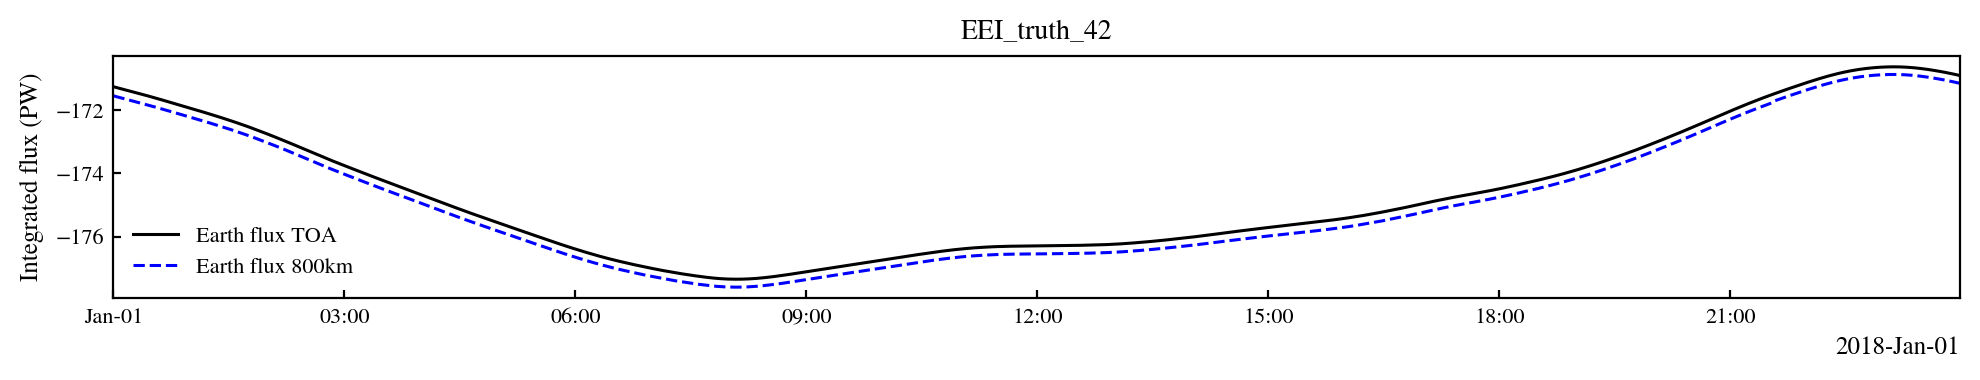

In [2]:
import numpy as np
import sys, os
from SpaceBalls.postproc_EEI_estimation import get_true_EEI_time_series, get_subdir_EEI_truth
from SpaceBalls.radiation_fluxes_preprocessing import compute_flux_hist_toa, get_r_sun_jd_hist, get_solar_incoming_day_hist, get_EEI_truth_daily_jd_arrays, F_vec_to_Fr, get_toa_grid_from_rad_config
from SpaceBalls.radiation_settings import get_TSI_1AU, radiation_settings_from_EEI_truth_name
from SpaceBalls.sph_meshing import QuadratureGrid, Grid
from SpaceBalls.utils import normal_smoother
from SpaceBalls.plotter import Plotter
%matplotlib inline

def get_solar_incoming(jd_array, rad_config: dict, grid: Grid, toa_grid: Grid):

    TSI_1AU_jd_array = get_TSI_1AU(jd_array, rad_config['TSI_source'])
    r_sun_hist = get_r_sun_jd_hist(rad_config, jd_array)
    solar_incoming_F_hist = get_solar_incoming_day_hist(
        r_sun_hist, TSI_1AU_jd_array, grid.stacked_grid_r, grid, 
        toa_grid=toa_grid, penumbra_method=rad_config.get('penumbra_method'))

    return solar_incoming_F_hist

def get_F_alt_hist(EEI_name, grid_altitude: Grid, frame="ECEF"):
    
    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    toa_grid = get_toa_grid_from_rad_config(rad_config)
    frame_tag = '' if frame=="ECEF" else "_SFF_accurate"
    all_F_hist = []

    for day_idx in range(n_days):
        # ECEF altitude:
        subdir_F = get_subdir_EEI_truth(EEI_name, 'daily_hist_net_F_800km'+frame_tag, grid_altitude.grid_name) 
        file_F_hist = os.path.join(subdir_F, 'day_'+str(day_idx)+'.npy')
        
        daily_hist_F = np.load(file_F_hist)
        if np.shape(daily_hist_F)[1]==3:
            daily_hist_F = np.moveaxis(daily_hist_F, 1, 2)
        all_F_hist.append(daily_hist_F)

    return np.concatenate(all_F_hist)


# EEI truths with a/e max. D/O 179
EEI_names = ['EEI_truth_3', 'EEI_truth_4', 'EEI_truth_42']
#grid_800km = QuadratureGrid(alt_km=800, order=201)
grid_800km = QuadratureGrid(alt_km=800, order=131)

n_days = 1
plot_solar = False
plot_earth = True

for EEI_name in EEI_names:
    rad_config = radiation_settings_from_EEI_truth_name(EEI_name)
    full_jd_array = np.concatenate(get_EEI_truth_daily_jd_arrays(rad_config['jd_interval'])[:n_days])
    
    # TOA fluxes:
    toa_grid = get_toa_grid_from_rad_config(rad_config)
    toa_LW_hist, toa_SW_hist, net_toa_hist = compute_flux_hist_toa(full_jd_array, rad_config, toa_grid)
    toa_earth_hist = -(toa_LW_hist + toa_SW_hist)
    toa_solar_hist = net_toa_hist - toa_earth_hist

    integrated_earth_toa_hist = toa_grid.compute_surf_integral(toa_earth_hist)
    integrated_solar_toa_hist = toa_grid.compute_surf_integral(toa_solar_hist)

    # altitude fluxes:
    net_F_alt_hist_ECEF = get_F_alt_hist(EEI_name, grid_800km, frame="ECEF")
    solar_F_alt_hist_ECEF = get_solar_incoming(full_jd_array, rad_config, grid_800km, toa_grid)
    earth_F_alt_hist_ECEF = net_F_alt_hist_ECEF - solar_F_alt_hist_ECEF
    solar_Fr_alt_hist_ECEF = F_vec_to_Fr(solar_F_alt_hist_ECEF, grid_800km.stacked_grid_u)
    earth_Fr_alt_hist_ECEF = F_vec_to_Fr(earth_F_alt_hist_ECEF, grid_800km.stacked_grid_u)

    integrated_solar_alt_hist = grid_800km.compute_surf_integral(solar_Fr_alt_hist_ECEF)
    integrated_earth_alt_hist = grid_800km.compute_surf_integral(earth_Fr_alt_hist_ECEF)

    # make figures
    if plot_earth:
        Plotter.plot_geo_data_new(toa_earth_hist[:,0], toa_grid, data_label='Earth emission F (W/m$^2$)',
                                add_coastlines=True, fade_coastlines=False, make_symmetric_cmap=False)
        
        Plotter.plot_geo_data_new(earth_Fr_alt_hist_ECEF[:,0], grid_800km, data_label='Earth emission F (W/m$^2$)',
                                add_coastlines=True, fade_coastlines=True, make_symmetric_cmap=False)
        
        Plotter.plot_time_series(full_jd_array,
            {'Earth flux TOA': integrated_earth_toa_hist*1e-9,
            'Earth flux 800km': integrated_earth_alt_hist*1e-9
            },
            f_width=2.5, f_height=0.5,
            ylabel='Integrated flux (PW)',
            title=EEI_name)    

    if plot_solar:
        Plotter.plot_geo_data_new(toa_solar_hist[:,0], toa_grid, data_label='Solar incoming F (W/m$^2$)',
                                add_coastlines=True, fade_coastlines=False, make_symmetric_cmap=True)
        
        Plotter.plot_geo_data_new(solar_Fr_alt_hist_ECEF[:,0], grid_800km, data_label='Solar incoming F (W/m$^2$)',
                                add_coastlines=True, fade_coastlines=True, make_symmetric_cmap=True)
        
        Plotter.plot_time_series(full_jd_array,
            {'Solar incoming flux TOA': integrated_solar_toa_hist*1e-9,
            'Solar incoming flux 800km': integrated_solar_alt_hist*1e-9
            },
            f_width=2.5, f_height=0.5,
            ylabel='Integrated flux (PW)',
            title=EEI_name)    
